Train a Logistic Regression model to predict whether a product will be recommended by applying feature engineering, balancing class distribution using SMOTE or undersampling, and optimizing for interpretability with regularization techniques.

Load and inspect the dataset

In [5]:
import pandas as pd
import numpy as np

In [6]:
df = pd.read_csv('task22_final_dataset.csv')

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["recommend_flag"].value_counts(dropna=False))

print("\nTarget percentages:")
print((df["recommend_flag"].value_counts(normalize=True) * 100).round(2))

print("\nMissing values in target:")
print(df["recommend_flag"].isna().sum())

display(df.head())


Dataset shape: (23483, 28)

Column names:
['product_id', 'category', 'subcategory1', 'subcategory2', 'location', 'channel', 'customer_age', 'review_title', 'review_text', 'rating', 'recommend_flag', 'vader_negative', 'vader_neutral', 'vader_positive', 'vader_compound', 'vader_sentiment_score', 'vader_sentiment_label', 'age_cluster_raw', 'age_group', 'sentiment_target', 'text_clean', 'text_stemmed', 'text_lemmatized', 'sentiment_standard', 'sentiment_quantile', 'sentiment_mean_based', 'vader_label_normalized', 'model_text']

Target distribution:
recommend_flag
1    19311
0     4172
Name: count, dtype: int64

Target percentages:
recommend_flag
1    82.23
0    17.77
Name: proportion, dtype: float64

Missing values in target:
0


,product_id,category,subcategory1,subcategory2,location,channel,customer_age,review_title,review_text,rating,...,age_group,sentiment_target,text_clean,text_stemmed,text_lemmatized,sentiment_standard,sentiment_quantile,sentiment_mean_based,vader_label_normalized,model_text
0,767,Initmates,Intimate,Intimates,Mumbai,Mobile,33,Not Provided,Absolutely wonderful - silky and sexy and comfortable,4,...,Age Group 2,Positive,absolutely wonderful silky and sexy and comfortable,absolut wonder silki and sexi and comfort,absolutely wonderful silky and sexy and comfortable,Positive,Negative,Neutral,Positive,Not Provided Absolutely wonderful - silky and sexy and comfortable
1,1080,General,Dresses,Dresses,Bangalore,Mobile,34,Not Provided,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite.",5,...,Age Group 2,Positive,love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite and am i love the length on me hits just a little below the knee would definitely be a true midi on someone who is truly petite,love this dress it s sooo pretti i happen to find it in a store and i m glad i did bc i never would have order it onlin bc it s petit i bought a petit and am i love the length on me hit just a littl below the knee would definit be a true midi on someon who is truli petit,love this dress it s sooo pretty i happened to find it in a store and i m glad i did bc i never would have ordered it online bc it s petite i bought a petite and am i love the length on me hit just a little below the knee would definitely be a true midi on someone who is truly petite,Positive,Positive,Positive,Positive,"Not Provided Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite. i bought a petite and am 5'8"". i love the length on me- hits just a little below the knee. would definitely be a true midi on someone who is truly petite."
2,1077,General,Dresses,Dresses,Gurgaon,Mobile,60,Some major design flaws,"I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall, the top half was comfortable and fit nicely, but the bottom half had a very tight under layer and several somewhat cheap (net) over layers. imo, a major design flaw was the net over layer sewn directly into the zipper - it c",3,...,Age Group 4,Neutral,i had such high hopes for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be outrageously small so small in fact that i could not zip it up i reordered it in petite medium which was just ok overall the top half was comfortable and fit nicely but the bottom half had a very tight under layer and several somewhat cheap net over layers imo a major design flaw was the net over layer sewn directly into the zipper it c,i had such high hope for this dress and realli want it to work for me i initi order the petit small my usual size but i found this to be outrag small so small in fact that i could not zip it up i reorder it in petit medium which was just ok overal the top half was comfort and fit nice but the bottom half had a veri tight under layer and sever somewhat cheap net over layer imo a major design flaw was the net over layer sewn direct into the zipper it c,i had such high hope for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be outrageously small so small in fact that i could not zip 

Select features and split the data

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
y = df['recommend_flag'].astype(int)

numeric_features = [
    "customer_age",
    "rating",
    "vader_negative",
    "vader_neutral",
    "vader_positive",
    "vader_compound",
    "vader_sentiment_score"
]

categorical_features = [
    "category",
    "subcategory1",
    "subcategory2",
    "location",
    "channel",
    "age_group",
    "vader_sentiment_label"
]

text_feature = 'model_text'

feature_columns = (numeric_features + categorical_features + [text_feature])
x = df[feature_columns].copy()


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nSelected feature count:", len(feature_columns))


Training data shape: (18786, 15)
Testing data shape: (4697, 15)

Training target distribution:
recommend_flag
1    15448
0     3338
Name: count, dtype: int64

Testing target distribution:
recommend_flag
1    3863
0     834
Name: count, dtype: int64

Selected feature count: 15


Data preprocessing

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

In [10]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
     ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
        ('text', TfidfVectorizer(max_features=3000), text_feature)
    ],
    remainder='drop'
)

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Training processed shape:", x_train_processed.shape)
print("Testing processed shape:", x_test_processed.shape)

Training processed shape: (18786, 3049)
Testing processed shape: (4697, 3049)


Handle class imbalance using SMOTE

In [11]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from imblearn.over_sampling import SMOTE
from collections import Counter

In [13]:
print('Before SMOTE: ', Counter(y_train))

smote = SMOTE(random_state=42)

x_train_balanced, y_train_balanced = smote.fit_resample(x_train_processed, y_train)

print("\nAfter SMOTE:", Counter(y_train_balanced))
print("Balanced training shape:", x_train_balanced.shape)
print("Testing shape (unchanged):", x_test_processed.shape)

Before SMOTE:  Counter({1: 15448, 0: 3338})

After SMOTE: Counter({0: 15448, 1: 15448})
Balanced training shape: (30896, 3049)
Testing shape (unchanged): (4697, 3049)


Train Logistic Regression with regularization

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [15]:
models = {
    'Logistic Regression L1': LogisticRegression(
        penalty='l1',
        C=1.0,
        solver='liblinear',
        max_iter=2000,
        random_state=42
    ),
    'Logistic Regression L2': LogisticRegression(
            penalty='l2',
            C=1.0,
            solver='liblinear',
            max_iter=2000,
            random_state=42
        )
}

results = []
trained_models = {}

for name, model in models.items():
    print("training: ", name)
    model.fit(x_train_balanced, y_train_balanced)
    y_pred = model.predict(x_test_processed)
    y_prob = model.predict_proba(x_test_processed)[:, 1]

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

training:  Logistic Regression L1


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


training:  Logistic Regression L2


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression L1,0.9402,0.9843,0.9423,0.9628,0.9784
1,Logistic Regression L2,0.9402,0.9862,0.9405,0.9628,0.9793


Confusion matrix and classification report

In [16]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

Classification Report:
                     precision    recall  f1-score   support

Not Recommended (0)       0.78      0.93      0.85       834
    Recommended (1)       0.98      0.94      0.96      3863

           accuracy                           0.94      4697
          macro avg       0.88      0.94      0.90      4697
       weighted avg       0.95      0.94      0.94      4697



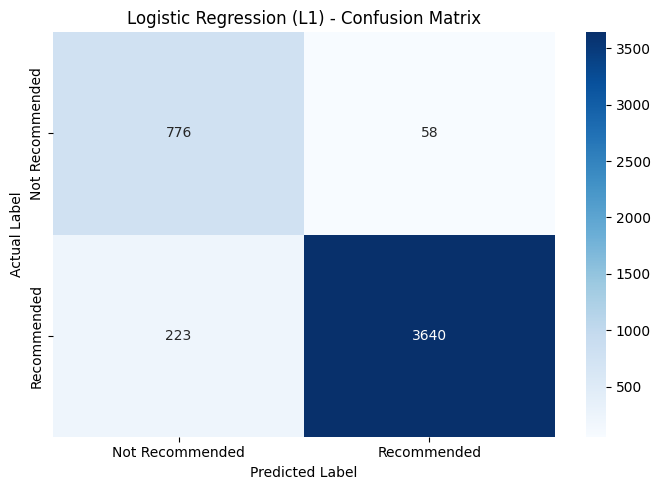

In [17]:
best_model = trained_models['Logistic Regression L1']

y_pred = best_model.predict(x_test_processed)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Not Recommended (0)", "Recommended (1)"]))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Recommended", "Recommended"],
    yticklabels=["Not Recommended", "Recommended"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression (L1) - Confusion Matrix")
plt.tight_layout()
plt.show()


Feature importance — interpretability

In [18]:
feature_names = preprocessor.get_feature_names_out()

# Get L1 model coefficients
coefficients = best_model.coef_[0]

# Create coefficient summary
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Largest positive coefficients
top_positive = feature_importance.sort_values(by='Coefficient', ascending=False).head(15)

# Largest negative coefficients
top_negative = feature_importance.sort_values(by='Coefficient', ascending=True).head(15)

print("Top 15 features associated with Recommendation:")
display(top_positive.round(4))

print("\nTop 15 features associated with Not Recommendation:")
display(top_negative.round(4))


Top 15 features associated with Recommendation:


,Feature,Coefficient
1819,text__order,5.7563
2339,text__silk,5.4742
2818,text__unique,5.3454
1749,text__nicely,5.2151
2973,text__with,4.6829
2419,text__soft,4.4302
2855,text__velvet,3.7038
1642,text__medium,3.6962
1665,text__mine,3.6953
2765,text__tts,3.6176



Top 15 features associated with Not Recommendation:


,Feature,Coefficient
2301,text__shocked,-6.1673
211,text__age,-5.9720
2139,text__returned,-5.6915
1646,text__meh,-5.4487
2277,text__shapeless,-4.9934
1268,text__happened,-4.9568
2445,text__space,-4.8643
1626,text__maternity,-4.8597
855,text__disappointed,-4.5400
1603,text__maeve,-4.5325


Conclusion 


The Logistic Regression model was successfully developed to predict product recommendations using numerical, categorical, and text features. Data preprocessing was performed using feature scaling, One-Hot Encoding, and TF-IDF vectorization. SMOTE was applied to balance the training dataset, and L1 and L2 regularization techniques were compared to improve model performance and interpretability. Both models achieved 94.02% accuracy and an F1-score of 96.28%. The L2 model achieved a ROC-AUC of 97.93%, while L1 regularization helped identify important positive and negative features through coefficient analysis. Overall, the results demonstrate that Logistic Regression can effectively predict product recommendations from customer reviews and product-related features.

In [19]:
import joblib
import os

In [20]:
save_folder = 'task31_saved_files'
os.makedirs(save_folder, exist_ok=True)

# Save L1 Logistic Regression model
joblib.dump(trained_models['Logistic Regression L1'], os.path.join(save_folder, 'logistic_regression_l1.pkl'))

# Save L2 Logistic Regression model
joblib.dump(trained_models['Logistic Regression L2'], os.path.join(save_folder, 'logistic_regression_l1.pkl'))

# Save fitted preprocessing pipeline
joblib.dump(preprocessor, os.path.join(save_folder, 'preprocessor.pkl'))

# Save feature configuration
feature_config = {
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "text_feature": text_feature,
    "target_column": "recommend_flag"
}

joblib.dump(feature_config, os.path.join(save_folder, 'feature_config.pkl'))

print("Task 31 files saved successfully!")
print("\nSaved files:")

for file in os.listdir(save_folder):
    print(file)


Task 31 files saved successfully!

Saved files:
feature_config.pkl
logistic_regression_l1.pkl
preprocessor.pkl
